# Website performance Data Analysis

In [3]:
# Importing all the libraries we need
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("data-export.csv")
df

,# ----------------------------------------,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,Session primary channel group (Default channel...,Date + hour (YYYYMMDDHH),Users,Sessions,Engaged sessions,Average engagement time per session,Engaged sessions per user,Events per session,Engagement rate,Event count
1,Direct,2024041623,237,300,144,47.526666666666700,0.6075949367088610,4.673333333333330,0.48,1402
2,Organic Social,2024041719,208,267,132,32.09737827715360,0.6346153846153850,4.295880149812730,0.4943820224719100,1147
3,Direct,2024041723,188,233,115,39.93991416309010,0.6117021276595740,4.587982832618030,0.49356223175965700,1069
4,Organic Social,2024041718,187,256,125,32.16015625,0.6684491978609630,4.078125,0.48828125,1044
...,...,...,...,...,...,...,...,...,...,...
3178,Unassigned,2024042806,0,1,0,0,0,2,0,2
3179,Unassigned,2024043005,0,1,0,0,0,2,0,2
3180,Unassigned,2024043006,0,1,0,0,0,2,0,2
3181,Unassigned,2024050105,0,1,0,0,0,2,0,2


In [5]:
# cleaning the untitled rows name 
df.columns = df.iloc[0]
df = df.drop(index = 0).reset_index(drop = True)
df.columns = ["Channel Group", "DateHour", "Users", "Sessions", "Engaged sessions", "Average engagement time per sessions", "Engaged sessions per users", "Events per sessions", "Engagement rate", "event count"]

In [6]:
df.head()

,Channel Group,DateHour,Users,Sessions,Engaged sessions,Average engagement time per sessions,Engaged sessions per users,Events per sessions,Engagement rate,event count
0,Direct,2024041623,237,300,144,47.526666666666700,0.6075949367088610,4.673333333333330,0.48,1402
1,Organic Social,2024041719,208,267,132,32.09737827715360,0.6346153846153850,4.295880149812730,0.4943820224719100,1147
2,Direct,2024041723,188,233,115,39.93991416309010,0.6117021276595740,4.587982832618030,0.49356223175965700,1069
3,Organic Social,2024041718,187,256,125,32.16015625,0.6684491978609630,4.078125,0.48828125,1044
4,Organic Social,2024041720,175,221,112,46.918552036199100,0.64,4.529411764705880,0.5067873303167420,1001


In [7]:
df['DateHour'] = pd.to_datetime(df['DateHour'], format = "%Y%m%d%H", errors = "coerce")
numeric_cols = df.columns.drop(["Channel Group", "DateHour"])
df[numeric_cols]  = df[numeric_cols].apply(pd.to_numeric, errors = "coerce")
df['Hour'] = df['DateHour'].dt.hour

In [8]:
df.head()

,Channel Group,DateHour,Users,Sessions,Engaged sessions,Average engagement time per sessions,Engaged sessions per users,Events per sessions,Engagement rate,event count,Hour
0,Direct,2024-04-16 23:00:00,237,300,144,47.526667,0.607595,4.673333,0.480000,1402,23
1,Organic Social,2024-04-17 19:00:00,208,267,132,32.097378,0.634615,4.295880,0.494382,1147,19
2,Direct,2024-04-17 23:00:00,188,233,115,39.939914,0.611702,4.587983,0.493562,1069,23
3,Organic Social,2024-04-17 18:00:00,187,256,125,32.160156,0.668449,4.078125,0.488281,1044,18
4,Organic Social,2024-04-17 20:00:00,175,221,112,46.918552,0.640000,4.529412,0.506787,1001,20


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3182 entries, 0 to 3181
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype         
---  ------                                --------------  -----         
 0   Channel Group                         3182 non-null   object        
 1   DateHour                              3182 non-null   datetime64[ns]
 2   Users                                 3182 non-null   int64         
 3   Sessions                              3182 non-null   int64         
 4   Engaged sessions                      3182 non-null   int64         
 5   Average engagement time per sessions  3182 non-null   float64       
 6   Engaged sessions per users            3182 non-null   float64       
 7   Events per sessions                   3182 non-null   float64       
 8   Engagement rate                       3182 non-null   float64       
 9   event count                           3182 non-null   int64         
 10  

In [10]:
df.describe()

,DateHour,Users,Sessions,Engaged sessions,Average engagement time per sessions,Engaged sessions per users,Events per sessions,Engagement rate,event count,Hour
count,3182,3182.000000,3182.000000,3182.000000,3182.000000,3182.000000,3182.000000,3182.000000,3182.000000,3182.000000
mean,2024-04-20 01:17:07.278441216,41.935889,51.192646,28.325581,66.644581,0.606450,4.675969,0.503396,242.272470,11.807040
min,2024-04-06 00:00:00,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000
25%,2024-04-13 02:15:00,20.000000,24.000000,13.000000,32.103034,0.561404,3.750000,0.442902,103.000000,6.000000
50%,2024-04-20 02:00:00,42.000000,51.000000,27.000000,49.020202,0.666667,4.410256,0.545455,226.000000,12.000000
75%,2024-04-26 22:00:00,60.000000,71.000000,41.000000,71.487069,0.750000,5.217690,0.633333,339.000000,18.000000
max,2024-05-03 23:00:00,237.000000,300.000000,144.000000,4525.000000,2.000000,56.000000,1.000000,1402.000000,23.000000
std,NaN,29.582258,36.919962,20.650569,127.200659,0.264023,2.795228,0.228206,184.440313,6.886686


# sessions and users over time 



In [12]:
sns.set(style = "whitegrid")


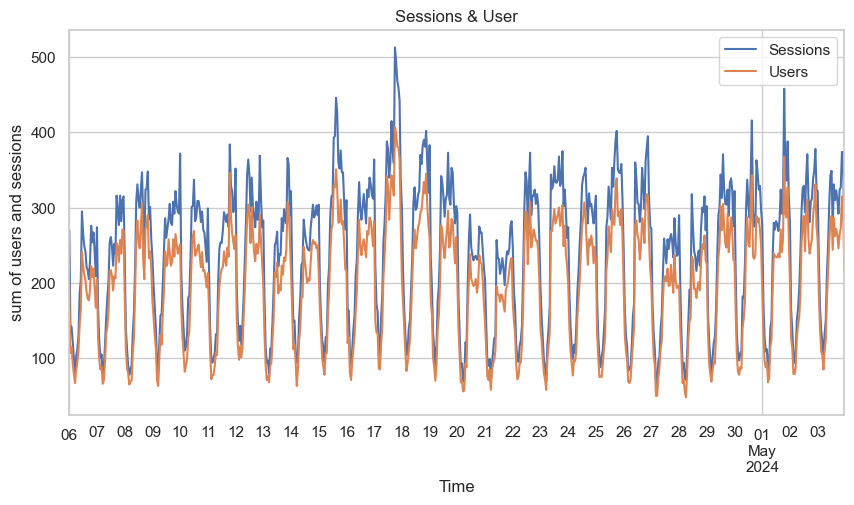

In [13]:
plt.figure(figsize = (10,5))
df.groupby("DateHour")[["Sessions", "Users"]].sum().plot(ax=plt.gca())
plt.title("Sessions & User")
plt.xlabel("Time")
plt.ylabel("sum of users and sessions")
plt.show()

In [14]:
df.head()

,Channel Group,DateHour,Users,Sessions,Engaged sessions,Average engagement time per sessions,Engaged sessions per users,Events per sessions,Engagement rate,event count,Hour
0,Direct,2024-04-16 23:00:00,237,300,144,47.526667,0.607595,4.673333,0.480000,1402,23
1,Organic Social,2024-04-17 19:00:00,208,267,132,32.097378,0.634615,4.295880,0.494382,1147,19
2,Direct,2024-04-17 23:00:00,188,233,115,39.939914,0.611702,4.587983,0.493562,1069,23
3,Organic Social,2024-04-17 18:00:00,187,256,125,32.160156,0.668449,4.078125,0.488281,1044,18
4,Organic Social,2024-04-17 20:00:00,175,221,112,46.918552,0.640000,4.529412,0.506787,1001,20


In [15]:
df['Channel Group'].unique()

array(['Direct', 'Organic Social', 'Organic Search', 'Referral',
       'Unassigned', 'Organic Video', 'Email'], dtype=object)

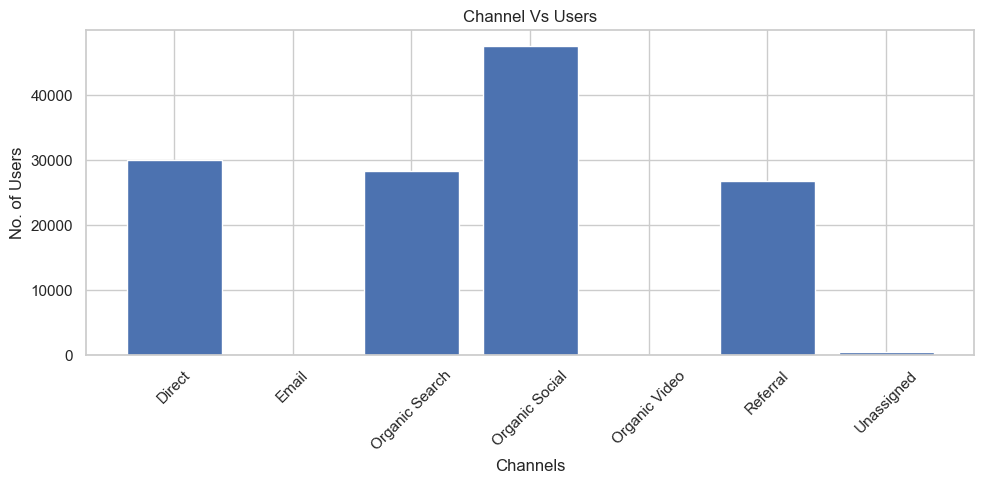

In [16]:
plt.figure(figsize=(10,5))
channel_users = df.groupby('Channel Group')['Users'].sum()
plt.bar(channel_users.index, channel_users.values)
plt.title("Channel Vs Users")
plt.xlabel("Channels")
plt.ylabel("No. of Users")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

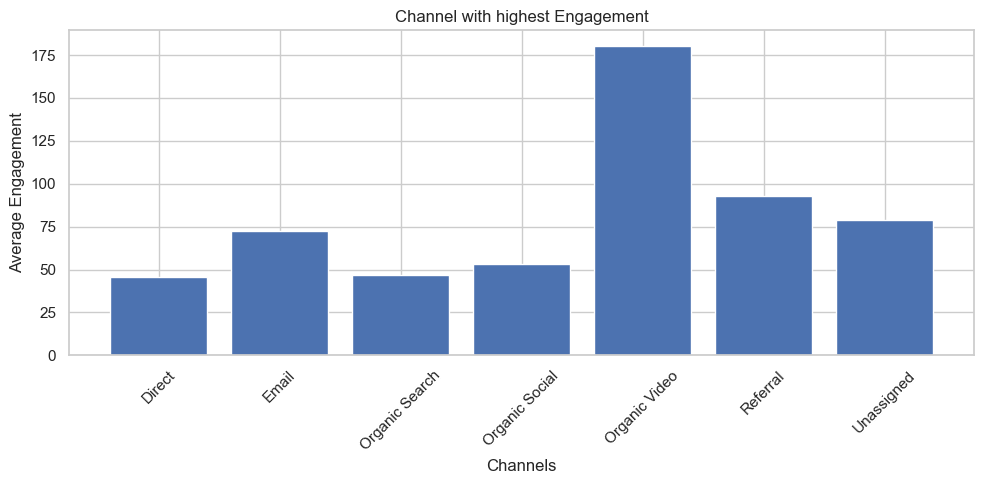

In [17]:
# which channel has the highest average engagement 
plt.figure(figsize=(10,5))
channel_engagement = df.groupby('Channel Group')['Average engagement time per sessions'].mean()
plt.bar(channel_engagement.index, channel_engagement.values)
plt.title("Channel with highest Engagement")
plt.xlabel("Channels")
plt.ylabel("Average Engagement")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

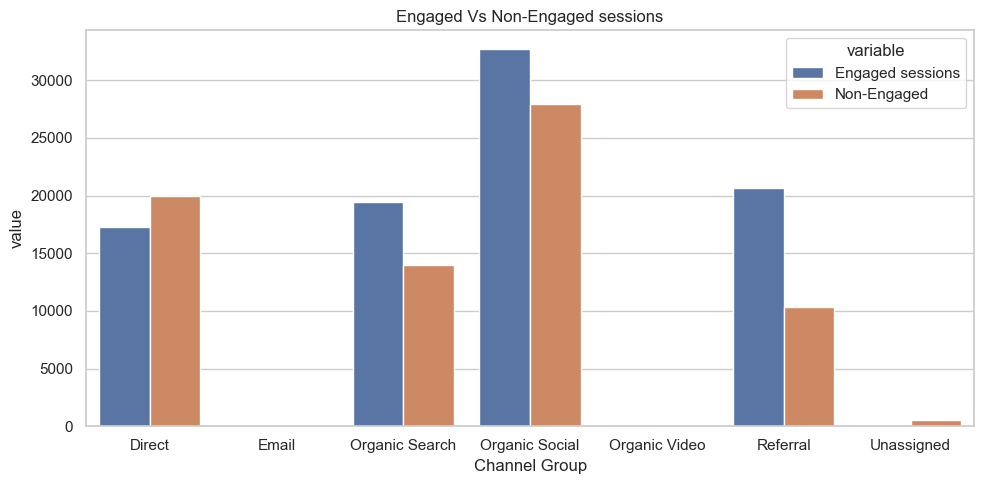

In [18]:
# Engaged Vs Non-engaged sessions 
sessions_df = df.groupby('Channel Group')[['Sessions', 'Engaged sessions']].sum().reset_index()
sessions_df['Non-Engaged'] = sessions_df['Sessions'] - sessions_df['Engaged sessions']
sessions_df_melted = sessions_df.melt(id_vars = 'Channel Group', value_vars = ['Engaged sessions', 'Non-Engaged'])

plt.figure(figsize=(10,5))
sns.barplot(data = sessions_df_melted, x = 'Channel Group', y = 'value', hue = 'variable')
plt.title("Engaged Vs Non-Engaged sessions")
plt.tight_layout()
plt.show()


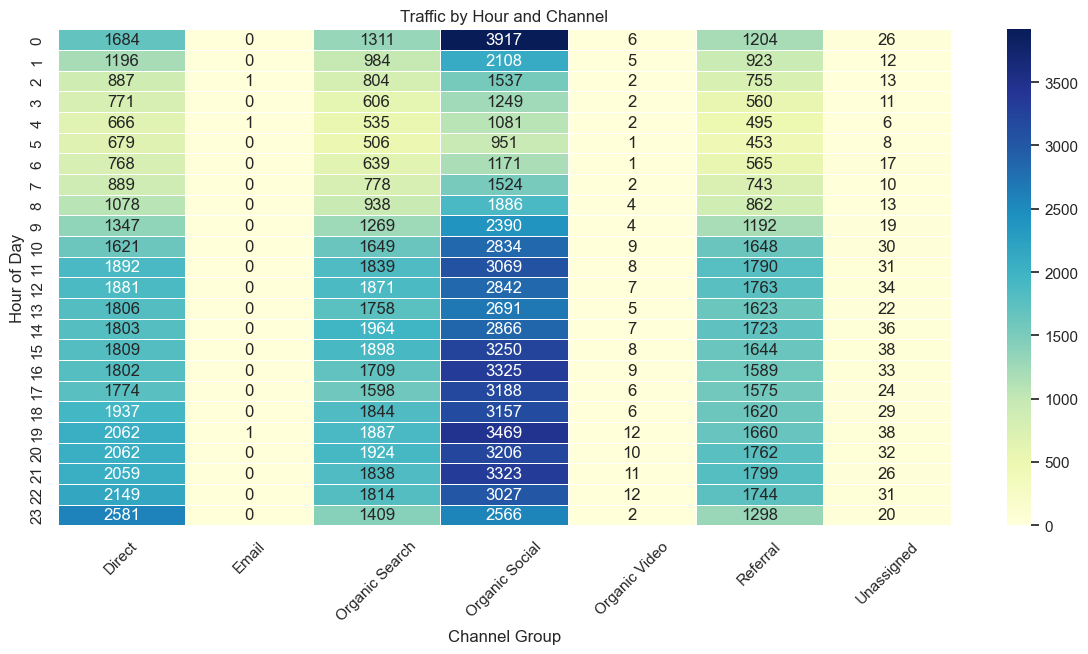

In [19]:
# Traffic By Hour and Channel
heatmap_data = df.groupby(["Hour", "Channel Group"])["Sessions"].sum().unstack().fillna(0)

plt.figure(figsize=(12,6))
sns.heatmap(heatmap_data, cmap='YlGnBu', linewidth=.5, annot=True, fmt='.0f')
plt.title("Traffic by Hour and Channel")
plt.xlabel("Channel Group")
plt.ylabel("Hour of Day")
plt.tight_layout()
plt.xticks(rotation=45)
plt.show()

In [20]:
df.head()

,Channel Group,DateHour,Users,Sessions,Engaged sessions,Average engagement time per sessions,Engaged sessions per users,Events per sessions,Engagement rate,event count,Hour
0,Direct,2024-04-16 23:00:00,237,300,144,47.526667,0.607595,4.673333,0.480000,1402,23
1,Organic Social,2024-04-17 19:00:00,208,267,132,32.097378,0.634615,4.295880,0.494382,1147,19
2,Direct,2024-04-17 23:00:00,188,233,115,39.939914,0.611702,4.587983,0.493562,1069,23
3,Organic Social,2024-04-17 18:00:00,187,256,125,32.160156,0.668449,4.078125,0.488281,1044,18
4,Organic Social,2024-04-17 20:00:00,175,221,112,46.918552,0.640000,4.529412,0.506787,1001,20


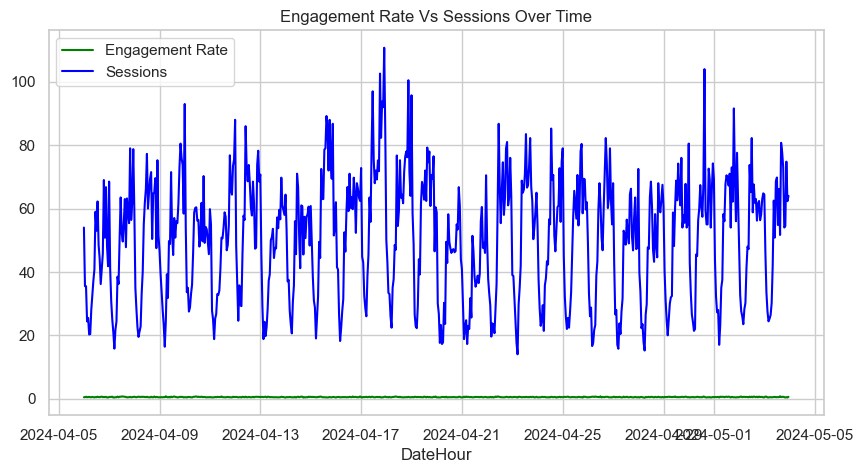

In [21]:
# Engagement rate Vs sessions over time 
df_plot = df.groupby('DateHour')[['Engagement rate', 'Sessions']].mean().reset_index()

plt.figure(figsize=(10,5))
plt.plot(df_plot['DateHour'], df_plot["Engagement rate"], label="Engagement Rate", color = "green")
plt.plot(df_plot['DateHour'], df_plot['Sessions'], label='Sessions', color='blue')
plt.title("Engagement Rate Vs Sessions Over Time")
plt.xlabel("DateHour")
plt.legend()
plt.grid(True)
plt.show()